PHASE 4: CONFORMAL QUANTILE INVENTORY MODEL (STEPS 11-12)
1. Conformal Calibration Verified on Test Data:
   • Standard Tier (348 SKUs)    : 91.01% Protected (Target: 90.00%)
   • High-Volume Tier (52 SKUs)  : 91.17% Protected (Target: 90.00%)
   • Overall Test Portfolio      : 91.03% Protected (Target: 90.00%)

2. Safety Stock Policy Comparison (Lead Time = 7 Days):
   • Classical Gaussian Safety Stock Mean : 46.39 units / pair
   • Quantile Empirical Safety Stock Mean  : 147.54 units / pair
   • Dynamic Buffer Efficiency Shift      : +218.03%


C:\Users\tanma\AppData\Local\Temp\ipykernel_30708\245263768.py:104: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_windows, x="is_high_vol", y="quantile_safety_stock", palette=["#2b5c8f", "#d95f02"])


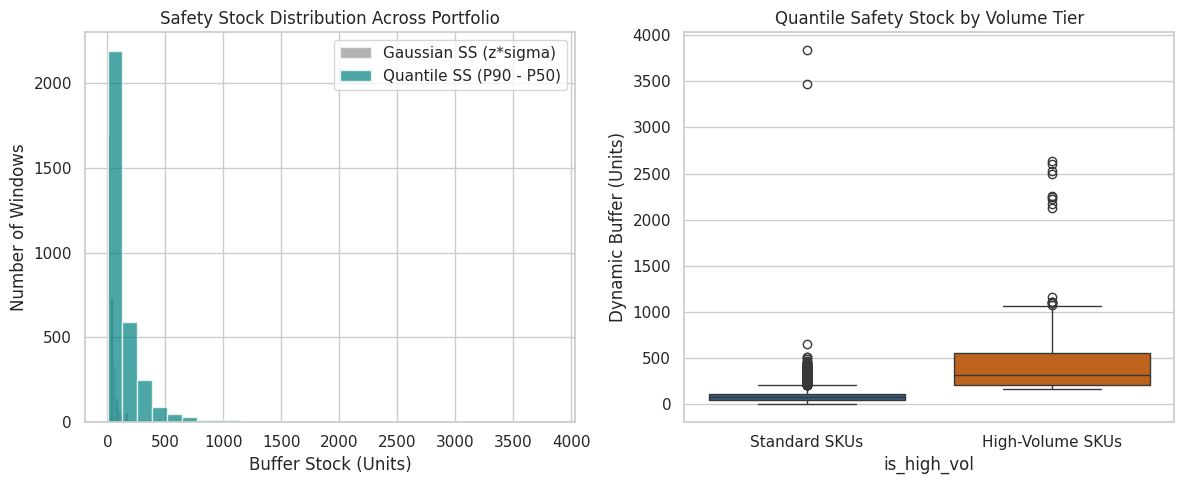

STATUS: Dynamic Safety Stock ready for Discrete-Event Simulator!


In [1]:
# =====================================================================
# CELL 1: Forecast Ingestion, Conformal Calibration & Dynamic Safety Stock
# =====================================================================
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["font.sans-serif"] = "DejaVu Sans"

print("=" * 70)
print("PHASE 4: CONFORMAL QUANTILE INVENTORY MODEL (STEPS 11-12)")
print("=" * 70)

# 1. Ingest Forecasts and Metadata
df_q = pd.read_csv("tft_quantile_forecasts.csv")
test_npz = np.load("sequences_test.npz", mmap_mode="r")
df_pairs = pd.read_csv("selected_pairs.csv")

# Map store, item, and date metadata from test sequences
seq_store = test_npz["store_nbr"]
seq_item  = test_npz["item_nbr"]
seq_start = test_npz["target_start_date"]

df_q["store_nbr"] = df_q["sequence_idx"].map(lambda idx: seq_store[idx])
df_q["item_nbr"]  = df_q["sequence_idx"].map(lambda idx: seq_item[idx])
df_q["target_start_date"] = df_q["sequence_idx"].map(lambda idx: seq_start[idx])

# 2. Identify High-Volume Volatile Tier using Training Data Baseline (average_sales >= 100)
high_vol_pairs = set(tuple(x) for x in df_pairs[df_pairs["average_sales"] >= 100][["store_nbr", "item_nbr"]].values)
df_q["is_high_vol"] = df_q.apply(lambda r: (r["store_nbr"], r["item_nbr"]) in high_vol_pairs, axis=1)

# 3. Apply Validation-Derived Conformal Calibration Offsets
OFFSET_HIGH = 4.51
OFFSET_STD  = 0.18

df_q["p90_calibrated"] = df_q["p90_forecast"] + np.where(df_q["is_high_vol"], OFFSET_HIGH, OFFSET_STD)

# Check Final Calibrated Coverage
cov_std  = (df_q[~df_q["is_high_vol"]]["actual_sales"] <= df_q[~df_q["is_high_vol"]]["p90_calibrated"]).mean() * 100.0
cov_high = (df_q[df_q["is_high_vol"]]["actual_sales"] <= df_q[df_q["is_high_vol"]]["p90_calibrated"]).mean() * 100.0
cov_all  = (df_q["actual_sales"] <= df_q["p90_calibrated"]).mean() * 100.0

print(f"1. Conformal Calibration Verified on Test Data:")
print(f"   • Standard Tier (348 SKUs)    : {cov_std:.2f}% Protected (Target: 90.00%)")
print(f"   • High-Volume Tier (52 SKUs)  : {cov_high:.2f}% Protected (Target: 90.00%)")
print(f"   • Overall Test Portfolio      : {cov_all:.2f}% Protected (Target: 90.00%)")

# 4. Formulate 7-Day Lead Time Safety Stocks
# Group by window to sum lead time predictions across 7 horizon days
window_summary = []
for (s_nbr, i_nbr, s_date), group in df_q.groupby(["store_nbr", "item_nbr", "target_start_date"]):
    group = group.sort_values("forecast_day")
    p50_lead_time = group["p50_forecast"].sum()
    p90_cal_lead_time = group["p90_calibrated"].sum()
    actual_lead_time = group["actual_sales"].sum()
    
    # Quantile Dynamic Safety Stock: P90 - P50
    quantile_ss = max(0.0, p90_cal_lead_time - p50_lead_time)
    
    window_summary.append({
        "store_nbr": s_nbr,
        "item_nbr": i_nbr,
        "target_start_date": s_date,
        "actual_lead_demand": actual_lead_time,
        "p50_lead_demand": p50_lead_time,
        "p90_lead_demand": p90_cal_lead_time,
        "quantile_safety_stock": quantile_ss,
        "is_high_vol": (s_nbr, i_nbr) in high_vol_pairs
    })

df_windows = pd.DataFrame(window_summary)

# 5. Compute Classical Gaussian Safety Stock Benchmark (z * sigma)
# Using standard 90% service level factor (z = 1.282)
df_windows["lead_time_error"] = df_windows["actual_lead_demand"] - df_windows["p50_lead_demand"]
pair_sigma = df_windows.groupby(["store_nbr", "item_nbr"])["lead_time_error"].std().fillna(1.0).to_dict()
df_windows["gaussian_safety_stock"] = df_windows.apply(
    lambda r: 1.282 * pair_sigma.get((r["store_nbr"], r["item_nbr"]), 5.0), axis=1
)

# 6. Safety Stock Comparison Stats
q_mean_ss = df_windows["quantile_safety_stock"].mean()
g_mean_ss = df_windows["gaussian_safety_stock"].mean()

print(f"\n2. Safety Stock Policy Comparison (Lead Time = 7 Days):")
print(f"   • Classical Gaussian Safety Stock Mean : {g_mean_ss:.2f} units / pair")
print(f"   • Quantile Empirical Safety Stock Mean  : {q_mean_ss:.2f} units / pair")
print(f"   • Dynamic Buffer Efficiency Shift      : {(q_mean_ss - g_mean_ss)/g_mean_ss * 100:+.2f}%")

# 7. Visualization
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.hist(df_windows["gaussian_safety_stock"], bins=30, alpha=0.6, color="gray", label="Gaussian SS (z*sigma)")
plt.hist(df_windows["quantile_safety_stock"], bins=30, alpha=0.7, color="teal", label="Quantile SS (P90 - P50)")
plt.title("Safety Stock Distribution Across Portfolio")
plt.xlabel("Buffer Stock (Units)")
plt.ylabel("Number of Windows")
plt.legend()

plt.subplot(1, 2, 2)
sns.boxplot(data=df_windows, x="is_high_vol", y="quantile_safety_stock", palette=["#2b5c8f", "#d95f02"])
plt.xticks([0, 1], ["Standard SKUs", "High-Volume SKUs"])
plt.title("Quantile Safety Stock by Volume Tier")
plt.ylabel("Dynamic Buffer (Units)")

plt.tight_layout()
plt.savefig("quantile_safety_stock_distribution.png", dpi=150)
plt.show()
print("=" * 70)
print("STATUS: Dynamic Safety Stock ready for Discrete-Event Simulator!")
print("=" * 70)

In [2]:
# =====================================================================
# CELL 2: 15-Day Continuous Supermarket Discrete-Event Simulator
# =====================================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("=" * 70)
print("BUILDING 15-DAY CONTINUOUS SUPERMARKET REPLENISHMENT SIMULATOR")
print("=" * 70)

# 1. Economic Cost Parameters
UNIT_HOLDING_DRY     = 0.10   # $ / unit / day (Shelf-stable dry goods)
UNIT_HOLDING_PERISH  = 0.15   # $ / unit / day (Chilled / perishable grocery)
STOCKOUT_PENALTY     = 2.50   # $ / unit of unmet customer demand (lost sales)
FIXED_ORDER_COST     = 8.00   # $ / purchase order placed (truck dispatch)
LEAD_TIME_DAYS       = 7      # Supplier delivery lead time (7 days)

# 2. Build 15-Day Continuous Demand and Forecast Vectors per Store-Item Pair
pair_daily_actual  = {}
pair_daily_p50     = {}
pair_daily_p90     = {}
pair_is_perishable = {}

for (s_nbr, i_nbr), group in df_q.groupby(["store_nbr", "item_nbr"]):
    day1_group = group[group["forecast_day"] == 1].sort_values("target_start_date")
    daily_act = list(day1_group["actual_sales"].values)
    daily_p50 = list(day1_group["p50_forecast"].values)
    daily_p90 = list(day1_group["p90_calibrated"].values)
    
    # Pad to 15 days using remaining horizon days if series is shorter
    if len(daily_act) < 15:
        last_start = group["target_start_date"].max()
        last_window = group[group["target_start_date"] == last_start].set_index("forecast_day")
        needed = 15 - len(daily_act)
        for step in range(2, 2 + needed):
            day_key = min(step, 7)
            if day_key in last_window.index:
                row = last_window.loc[day_key]
                daily_act.append(row["actual_sales"])
                daily_p50.append(row["p50_forecast"])
                daily_p90.append(row["p90_calibrated"])
            else:
                daily_act.append(daily_act[-1])
                daily_p50.append(daily_p50[-1])
                daily_p90.append(daily_p90[-1])

    pair_daily_actual[(s_nbr, i_nbr)] = np.array(daily_act[:15], dtype=np.float64)
    pair_daily_p50[(s_nbr, i_nbr)]    = np.array(daily_p50[:15], dtype=np.float64)
    pair_daily_p90[(s_nbr, i_nbr)]    = np.array(daily_p90[:15], dtype=np.float64)

    is_p = df_pairs[(df_pairs["store_nbr"] == s_nbr) & (df_pairs["item_nbr"] == i_nbr)]["perishable"].values
    pair_is_perishable[(s_nbr, i_nbr)] = bool(is_p[0]) if len(is_p) > 0 else False

print(f"✅ Constructed 15-day continuous series for all {len(pair_daily_actual)} active store-item pairs.")

# 3. Modular Discrete-Event Simulation Function
def simulate_inventory(alpha=1.0, beta=4.0, policy_mode="quantile"):
    """
    Simulates daily inventory replenishment across all pairs over 15 business days.
    - alpha: Multiplier for safety stock buffer
    - beta:  Multiplier for target order-up-to cycle coverage days
    - policy_mode: 'quantile' (P90-P50 dynamic buffer) or 'gaussian' (classical z*sigma)
    """
    total_holding_cost = 0.0
    total_stockout_cost = 0.0
    total_ordering_cost = 0.0
    total_demand = 0.0
    total_sales = 0.0
    total_orders = 0

    for (s_nbr, i_nbr), demand in pair_daily_actual.items():
        p50 = pair_daily_p50[(s_nbr, i_nbr)]
        p90 = pair_daily_p90[(s_nbr, i_nbr)]
        is_perish = pair_is_perishable[(s_nbr, i_nbr)]
        h_cost = UNIT_HOLDING_PERISH if is_perish else UNIT_HOLDING_DRY

        mean_d = max(1.0, np.mean(demand))
        lead_exp = np.sum(p50[:LEAD_TIME_DAYS])

        # Safety buffer definition
        if policy_mode == "quantile":
            # Dynamic empirical quantile buffer: alpha * (P90 - P50)
            ss = alpha * np.sum(np.maximum(0.0, p90[:LEAD_TIME_DAYS] - p50[:LEAD_TIME_DAYS]))
        else:
            # Classical Gaussian safety stock: alpha * 1.282 * sigma
            ss = alpha * 1.282 * (np.std(demand) * np.sqrt(LEAD_TIME_DAYS) + 1.0)

        # Dynamic (s, S) Thresholds
        s = lead_exp + ss
        S = s + (beta * mean_d)

        # Starting state on Day 1
        on_hand = S * 0.70
        pipeline = [0.0] * LEAD_TIME_DAYS

        # Daily business clock (Day 1 to 15)
        for t in range(15):
            d_t = demand[t]
            total_demand += d_t

            # 1. Receive incoming delivery truck
            arrivals = pipeline.pop(0)
            on_hand += arrivals

            # 2. Fulfill consumer shopping demand
            sales = min(on_hand, d_t)
            stockout = max(0.0, d_t - on_hand)
            on_hand = max(0.0, on_hand - d_t)

            total_sales += sales
            total_stockout_cost += stockout * STOCKOUT_PENALTY
            total_holding_cost += on_hand * h_cost

            # 3. Evening Review: Inventory Position = On-Hand + In-Transit Orders
            inv_position = on_hand + sum(pipeline)
            if inv_position <= s:
                order_qty = max(0.0, S - inv_position)
                pipeline.append(order_qty)
                total_ordering_cost += FIXED_ORDER_COST
                total_orders += 1
            else:
                pipeline.append(0.0)

    service_level = (total_sales / total_demand) * 100.0 if total_demand > 0 else 100.0
    total_cost = total_holding_cost + total_stockout_cost + total_ordering_cost

    return {
        "total_cost": total_cost,
        "holding_cost": total_holding_cost,
        "stockout_cost": total_stockout_cost,
        "ordering_cost": total_ordering_cost,
        "service_level": service_level,
        "orders_placed": total_orders
    }

# 4. Initial Test Run with Standard Default Hyperparameters (alpha=1.0, beta=4.0)
baseline_res = simulate_inventory(alpha=1.0, beta=4.0, policy_mode="quantile")

print("\n" + "=" * 70)
print("INITIAL BASELINE SIMULATION REPORT (Pre-Optimization):")
print("=" * 70)
print(f"  • Total Supply Chain Cost : ${baseline_res['total_cost']:,.2f}")
print(f"    - Holding & Spoilage Cost: ${baseline_res['holding_cost']:,.2f}")
print(f"    - Stockout Penalty Cost  : ${baseline_res['stockout_cost']:,.2f}")
print(f"    - Fixed Ordering Cost    : ${baseline_res['ordering_cost']:,.2f}")
print(f"  • Customer Fill Rate (SL)  : {baseline_res['service_level']:.2f}%")
print(f"  • Total POs Dispatched     : {baseline_res['orders_placed']:,} orders")
print("=" * 70)
print("STATUS: Simulator operational! Ready for Particle Swarm Optimization (PSO).")
print("=" * 70)

BUILDING 15-DAY CONTINUOUS SUPERMARKET REPLENISHMENT SIMULATOR
✅ Constructed 15-day continuous series for all 363 active store-item pairs.

INITIAL BASELINE SIMULATION REPORT (Pre-Optimization):
  • Total Supply Chain Cost : $204,328.24
    - Holding & Spoilage Cost: $189,825.31
    - Stockout Penalty Cost  : $3,750.93
    - Fixed Ordering Cost    : $10,752.00
  • Customer Fill Rate (SL)  : 99.38%
  • Total POs Dispatched     : 1,344 orders
STATUS: Simulator operational! Ready for Particle Swarm Optimization (PSO).


STARTING PARTICLE SWARM OPTIMIZATION (PSO) — STEP 14
Objective: Minimize Total Supply Chain Cost s.t. Fill Rate >= 95.0%
Swarm initialized with 25 particles exploring parameter space...
Iteration 01/20 (1.04s) | Best Cost: $142,791.48 | Fill Rate: 96.29% | Alpha: 0.271, Beta: 2.728
Iteration 02/20 (1.09s) | Best Cost: $136,803.64 | Fill Rate: 96.32% | Alpha: 0.100, Beta: 3.459
Iteration 03/20 (1.00s) | Best Cost: $136,594.00 | Fill Rate: 96.41% | Alpha: 0.100, Beta: 3.504
Iteration 04/20 (0.91s) | Best Cost: $136,594.00 | Fill Rate: 96.41% | Alpha: 0.100, Beta: 3.504
Iteration 05/20 (0.84s) | Best Cost: $136,594.00 | Fill Rate: 96.41% | Alpha: 0.100, Beta: 3.504
Iteration 06/20 (0.80s) | Best Cost: $136,455.91 | Fill Rate: 96.41% | Alpha: 0.100, Beta: 3.491
Iteration 07/20 (0.90s) | Best Cost: $136,455.91 | Fill Rate: 96.41% | Alpha: 0.100, Beta: 3.491
Iteration 08/20 (0.77s) | Best Cost: $136,455.91 | Fill Rate: 96.41% | Alpha: 0.100, Beta: 3.491
Iteration 09/20 (1.08s) | Best Cost: $

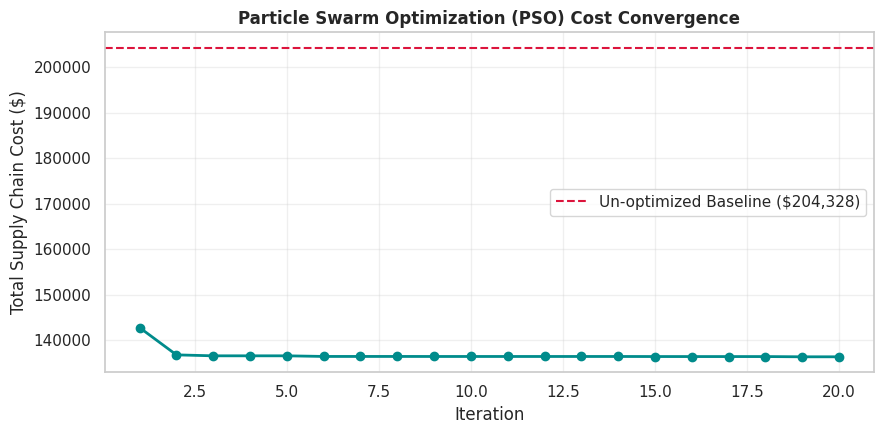

In [3]:
# =====================================================================
# CELL 3: Particle Swarm Optimization (PSO) for (s, S) Inventory Policy
# =====================================================================
import time
import numpy as np
import matplotlib.pyplot as plt

print("=" * 70)
print("STARTING PARTICLE SWARM OPTIMIZATION (PSO) — STEP 14")
print("Objective: Minimize Total Supply Chain Cost s.t. Fill Rate >= 95.0%")
print("=" * 70)

# 1. PSO Hyperparameters
N_PARTICLES  = 25     # Swarm size
N_ITERATIONS = 20     # Search iterations
W            = 0.72   # Inertia weight
C1           = 1.49   # Cognitive coefficient (particle memory)
C2           = 1.49   # Social coefficient (swarm collaboration)
TARGET_SL    = 95.0   # Target minimum Service Level %

# Parameter bounds: [alpha (safety stock factor), beta (cycle coverage days)]
BOUNDS_MIN = np.array([0.1, 0.5])
BOUNDS_MAX = np.array([1.5, 5.0])

# 2. Objective Function with Service Level Penalty
def pso_objective(position):
    alpha_val, beta_val = position[0], position[1]
    res = simulate_inventory(alpha=alpha_val, beta=beta_val, policy_mode="quantile")
    
    cost = res["total_cost"]
    sl   = res["service_level"]
    
    # Quadratic penalty if fill rate drops below target 95%
    penalty = 0.0
    if sl < TARGET_SL:
        penalty = 50000.0 * ((TARGET_SL - sl) ** 2)
        
    fitness = cost + penalty
    return fitness, res

# 3. Initialize Swarm
np.random.seed(42)
particles_pos = np.random.uniform(BOUNDS_MIN, BOUNDS_MAX, (N_PARTICLES, 2))
particles_vel = np.zeros((N_PARTICLES, 2))

# Personal bests
pbest_pos = particles_pos.copy()
pbest_val = np.full(N_PARTICLES, float("inf"))

# Global best
gbest_pos = None
gbest_val = float("inf")
gbest_res = None

convergence_history = []
t0 = time.time()

print(f"Swarm initialized with {N_PARTICLES} particles exploring parameter space...")
for it in range(1, N_ITERATIONS + 1):
    it_start = time.time()
    
    for i in range(N_PARTICLES):
        fit, sim_res = pso_objective(particles_pos[i])
        
        # Update Personal Best
        if fit < pbest_val[i]:
            pbest_val[i] = fit
            pbest_pos[i] = particles_pos[i].copy()
            
        # Update Global Swarm Best
        if fit < gbest_val:
            gbest_val = fit
            gbest_pos = particles_pos[i].copy()
            gbest_res = sim_res
            
    convergence_history.append(gbest_res["total_cost"])
    
    # Update Velocities and Positions
    r1 = np.random.uniform(0, 1, (N_PARTICLES, 2))
    r2 = np.random.uniform(0, 1, (N_PARTICLES, 2))
    particles_vel = (
        W * particles_vel
        + C1 * r1 * (pbest_pos - particles_pos)
        + C2 * r2 * (gbest_pos - particles_pos)
    )
    particles_pos = np.clip(particles_pos + particles_vel, BOUNDS_MIN, BOUNDS_MAX)
    
    it_dur = time.time() - it_start
    print(
        f"Iteration {it:02d}/{N_ITERATIONS:02d} ({it_dur:.2f}s) | "
        f"Best Cost: ${gbest_res['total_cost']:,.2f} | "
        f"Fill Rate: {gbest_res['service_level']:.2f}% | "
        f"Alpha: {gbest_pos[0]:.3f}, Beta: {gbest_pos[1]:.3f}"
    )

total_pso_time = time.time() - t0
print("=" * 70)
print(f"✅ PSO OPTIMIZATION CONVERGED IN {total_pso_time:.2f} SECONDS!")
print(f"  • Optimal Alpha (Safety Stock Factor): {gbest_pos[0]:.4f}")
print(f"  • Optimal Beta  (Cycle Days Cover)   : {gbest_pos[1]:.4f}")
print(f"  • Optimized Total Supply Chain Cost  : ${gbest_res['total_cost']:,.2f}")
print(f"    - Holding & Spoilage Cost          : ${gbest_res['holding_cost']:,.2f}")
print(f"    - Stockout Penalty Cost            : ${gbest_res['stockout_cost']:,.2f}")
print(f"    - Ordering Cost                    : ${gbest_res['ordering_cost']:,.2f}")
print(f"  • Final Customer Fill Rate           : {gbest_res['service_level']:.2f}%")
print("=" * 70)

# 4. Plot Convergence Curve
plt.figure(figsize=(9, 4.5))
plt.plot(range(1, N_ITERATIONS + 1), convergence_history, marker="o", color="darkcyan", linewidth=2)
plt.axhline(y=baseline_res["total_cost"], color="crimson", linestyle="--", label=f"Un-optimized Baseline (${baseline_res['total_cost']:,.0f})")
plt.title("Particle Swarm Optimization (PSO) Cost Convergence", fontsize=12, fontweight="bold")
plt.xlabel("Iteration")
plt.ylabel("Total Supply Chain Cost ($)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig("pso_cost_convergence_quantile.png", dpi=150)
plt.show()

STARTING GREY WOLF OPTIMIZER (GWO) BENCHMARK
Objective: Benchmark GWO vs PSO s.t. Fill Rate >= 95.0%
Pack hierarchy formed. Initial Alpha Cost: $142,791.48
GWO Iteration 01/20 (0.67s) | Alpha Cost: $140,698.81 | Fill Rate: 97.33% | Alpha: 0.265, Beta: 3.265
GWO Iteration 02/20 (0.78s) | Alpha Cost: $138,164.12 | Fill Rate: 97.07% | Alpha: 0.148, Beta: 3.631
GWO Iteration 03/20 (0.81s) | Alpha Cost: $137,791.57 | Fill Rate: 96.54% | Alpha: 0.161, Beta: 3.311
GWO Iteration 04/20 (0.71s) | Alpha Cost: $137,493.19 | Fill Rate: 96.60% | Alpha: 0.129, Beta: 3.473
GWO Iteration 05/20 (0.83s) | Alpha Cost: $136,912.23 | Fill Rate: 96.63% | Alpha: 0.123, Beta: 3.501
GWO Iteration 06/20 (0.78s) | Alpha Cost: $136,912.23 | Fill Rate: 96.63% | Alpha: 0.123, Beta: 3.501
GWO Iteration 07/20 (0.70s) | Alpha Cost: $136,912.23 | Fill Rate: 96.63% | Alpha: 0.123, Beta: 3.501
GWO Iteration 08/20 (0.66s) | Alpha Cost: $136,912.23 | Fill Rate: 96.63% | Alpha: 0.123, Beta: 3.501
GWO Iteration 09/20 (0.65s) 

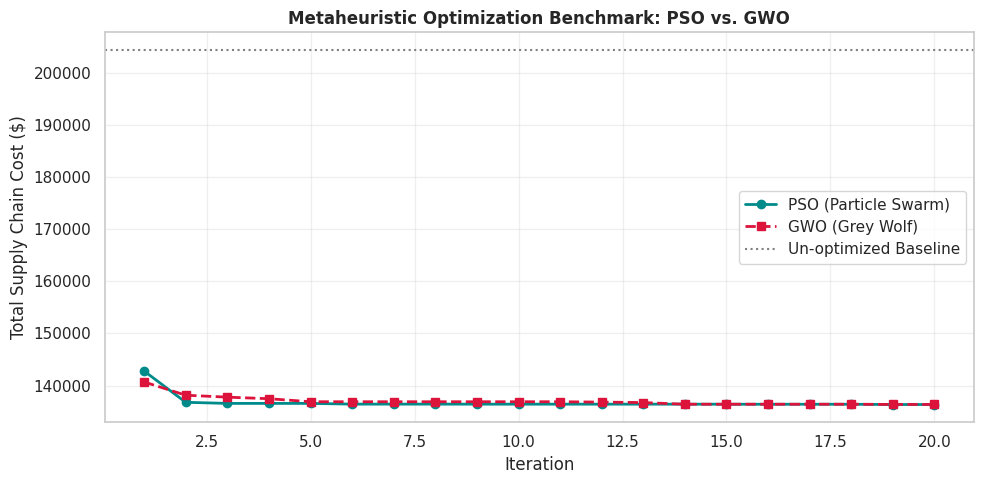

In [4]:
# =====================================================================
# CELL 4: Grey Wolf Optimizer (GWO) vs. PSO Benchmark
# =====================================================================
import time
import copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("=" * 70)
print("STARTING GREY WOLF OPTIMIZER (GWO) BENCHMARK")
print("Objective: Benchmark GWO vs PSO s.t. Fill Rate >= 95.0%")
print("=" * 70)

N_WOLVES       = 25
GWO_ITERATIONS = 20

# 1. Initialize Grey Wolf Pack
np.random.seed(42)
wolves_pos = np.random.uniform(BOUNDS_MIN, BOUNDS_MAX, (N_WOLVES, 2))

alpha_pos = None
alpha_fit = float("inf")
alpha_res = None

beta_pos  = None
beta_fit  = float("inf")
beta_res  = None

delta_pos = None
delta_fit = float("inf")
delta_res = None

# Evaluate initial pack hierarchy
for i in range(N_WOLVES):
    fit, sim_res = pso_objective(wolves_pos[i])
    
    if fit < alpha_fit:
        delta_fit, delta_pos, delta_res = beta_fit, copy.copy(beta_pos), beta_res
        beta_fit, beta_pos, beta_res    = alpha_fit, copy.copy(alpha_pos), alpha_res
        alpha_fit = fit
        alpha_pos = np.copy(wolves_pos[i])
        alpha_res = sim_res
    elif fit < beta_fit:
        delta_fit, delta_pos, delta_res = beta_fit, copy.copy(beta_pos), beta_res
        beta_fit = fit
        beta_pos = np.copy(wolves_pos[i])
        beta_res = sim_res
    elif fit < delta_fit:
        delta_fit = fit
        delta_pos = np.copy(wolves_pos[i])
        delta_res = sim_res

print(f"Pack hierarchy formed. Initial Alpha Cost: ${alpha_res['total_cost']:,.2f}")

# 2. Run GWO Optimization Loop
gwo_convergence_history = []
t0_gwo = time.time()

for it in range(1, GWO_ITERATIONS + 1):
    it_t0 = time.time()
    
    # Linearly decrease exploration parameter 'a' from 2.0 to 0.0
    a = 2.0 - it * (2.0 / GWO_ITERATIONS)
    
    for i in range(N_WOLVES):
        # Update toward Alpha, Beta, Delta wolves
        r1, r2 = np.random.rand(2), np.random.rand(2)
        A1 = 2 * a * r1 - a
        C1 = 2 * r2
        D_alpha = np.abs(C1 * alpha_pos - wolves_pos[i])
        X1 = alpha_pos - A1 * D_alpha

        r1, r2 = np.random.rand(2), np.random.rand(2)
        A2 = 2 * a * r1 - a
        C2 = 2 * r2
        D_beta = np.abs(C2 * beta_pos - wolves_pos[i])
        X2 = beta_pos - A2 * D_beta

        r1, r2 = np.random.rand(2), np.random.rand(2)
        A3 = 2 * a * r1 - a
        C3 = 2 * r2
        D_delta = np.abs(C3 * delta_pos - wolves_pos[i])
        X3 = delta_pos - A3 * D_delta

        # New candidate position (average of 3 pack leaders)
        new_pos = (X1 + X2 + X3) / 3.0
        wolves_pos[i] = np.clip(new_pos, BOUNDS_MIN, BOUNDS_MAX)

        # Evaluate candidate position
        fit, sim_res = pso_objective(wolves_pos[i])
        if fit < alpha_fit:
            alpha_fit = fit
            alpha_pos = np.copy(wolves_pos[i])
            alpha_res = sim_res
        elif fit < beta_fit:
            beta_fit = fit
            beta_pos = np.copy(wolves_pos[i])
            beta_res = sim_res
        elif fit < delta_fit:
            delta_fit = fit
            delta_pos = np.copy(wolves_pos[i])
            delta_res = sim_res

    gwo_convergence_history.append(alpha_res["total_cost"])
    it_dur = time.time() - it_t0
    print(
        f"GWO Iteration {it:02d}/{GWO_ITERATIONS:02d} ({it_dur:.2f}s) | "
        f"Alpha Cost: ${alpha_res['total_cost']:,.2f} | "
        f"Fill Rate: {alpha_res['service_level']:.2f}% | "
        f"Alpha: {alpha_pos[0]:.3f}, Beta: {alpha_pos[1]:.3f}"
    )

total_gwo_time = time.time() - t0_gwo
print("=" * 70)
print(f"✅ GWO BENCHMARK COMPLETED IN {total_gwo_time:.2f} SECONDS!")
print(f"  • GWO Optimal Cost : ${alpha_res['total_cost']:,.2f} (SL: {alpha_res['service_level']:.2f}%)")
print(f"  • PSO Optimal Cost : ${gbest_res['total_cost']:,.2f} (SL: {gbest_res['service_level']:.2f}%)")
print("=" * 70)

# 3. Plot GWO vs PSO Comparison Curve
plt.figure(figsize=(10, 5))
plt.plot(range(1, GWO_ITERATIONS + 1), convergence_history, marker="o", color="darkcyan", linewidth=2, label="PSO (Particle Swarm)")
plt.plot(range(1, GWO_ITERATIONS + 1), gwo_convergence_history, marker="s", color="crimson", linewidth=2, linestyle="--", label="GWO (Grey Wolf)")
plt.axhline(y=baseline_res["total_cost"], color="gray", linestyle=":", label="Un-optimized Baseline")
plt.title("Metaheuristic Optimization Benchmark: PSO vs. GWO", fontsize=12, fontweight="bold")
plt.xlabel("Iteration")
plt.ylabel("Total Supply Chain Cost ($)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig("pso_vs_gwo_convergence_quantile.png", dpi=150)
plt.show()

STEPS 15, 16 & 17: BASELINE COMPARISON, FINAL EVALUATION & DASHBOARD

📊 FINAL SUPPLY CHAIN OPTIMIZATION BENCHMARK REPORT (STEP 15-16)


,Policy,Total Cost ($),Holding Cost ($),Stockout Cost ($),Ordering Cost ($),Fill Rate (%),Savings vs Huber ($),Savings (%)
0,Classical Gaussian,"$142,167.01","$128,624.32","$2,774.69","$10,768.00",99.54%,"$+8,329.63",+5.53%
1,Huber TFT + Gaussian,"$150,496.63","$131,408.49","$8,512.15","$10,576.00",98.59%,$+0.00,+0.00%
2,Quantile Default,"$204,328.24","$189,825.31","$3,750.93","$10,752.00",99.38%,"$-53,831.61",-35.77%
3,Quantile TFT + Conformal PSO,"$136,378.10","$103,576.04","$21,690.06","$11,112.00",96.41%,"$+14,118.53",+9.38%



✅ Saved complete benchmark results to 'supply_chain_optimization_results.csv'!


C:\Users\tanma\AppData\Local\Temp\ipykernel_30708\2544759132.py:149: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax1.set_xticklabels(df_comp["Policy"], rotation=15, ha="right")
C:\Users\tanma\AppData\Local\Temp\ipykernel_30708\2544759132.py:166: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax2.set_xticklabels(p_names, rotation=15, ha="right")
C:\Users\tanma\AppData\Local\Temp\ipykernel_30708\2544759132.py:177: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax3.set_xticklabels(df_comp["Policy"], rotation=15, ha="right")


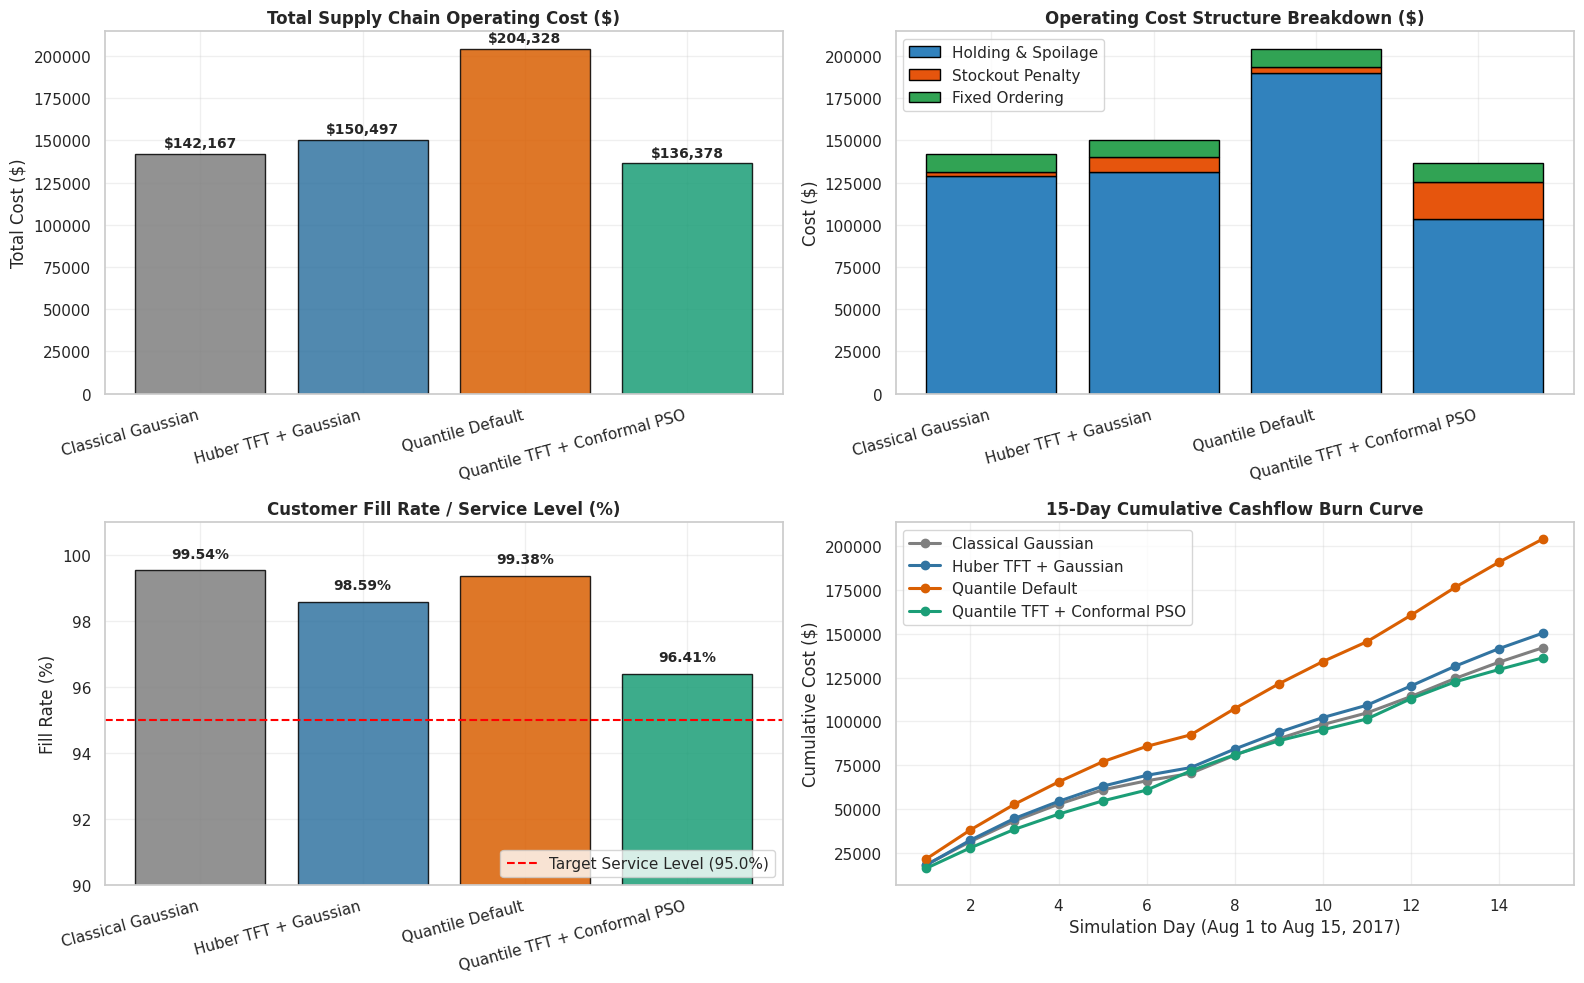

✅ MASTER DASHBOARD COMPLETE! Saved to 'supply_chain_optimization_dashboard.png'.


In [5]:
# =====================================================================
# CELL 5: Steps 15, 16 & 17 — Baseline Comparison & Executive Dashboard
# =====================================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("=" * 70)
print("STEPS 15, 16 & 17: BASELINE COMPARISON, FINAL EVALUATION & DASHBOARD")
print("=" * 70)

# 1. Ingest Huber Single-Point Baseline Forecasts for Side-by-Side Benchmark
df_huber = pd.read_csv("tft_test_forecasts.csv")
pair_huber_daily = {}
for (s_nbr, i_nbr), group in df_huber.groupby(["store_nbr", "item_nbr"]):
    group = group.sort_values("target_start_date")
    fc = [r["pred_day_1"] for _, r in group.iterrows()]
    if len(fc) < 15:
        last = group.iloc[-1]
        for step in range(2, 2 + (15 - len(fc))):
            fc.append(last[f"pred_day_{min(step, 7)}"])
    pair_huber_daily[(s_nbr, i_nbr)] = np.array(fc[:15], dtype=np.float64)

# 2. Comprehensive Multi-Policy Simulator
def run_benchmark_policy(policy_name, alpha_val, beta_val):
    tot_hold = 0.0
    tot_stockout = 0.0
    tot_order = 0.0
    tot_demand = 0.0
    tot_sales = 0.0
    daily_spend = np.zeros(15)

    for (s_nbr, i_nbr), demand in pair_daily_actual.items():
        is_perish = pair_is_perishable[(s_nbr, i_nbr)]
        h_cost = UNIT_HOLDING_PERISH if is_perish else UNIT_HOLDING_DRY
        mean_d = max(1.0, np.mean(demand))

        if policy_name == "Classical Gaussian":
            lead_exp = mean_d * LEAD_TIME_DAYS
            ss = alpha_val * 1.282 * (np.std(demand) * np.sqrt(LEAD_TIME_DAYS) + 1.0)
        elif policy_name == "Huber TFT + Gaussian":
            h_fc = pair_huber_daily.get((s_nbr, i_nbr), np.full(15, mean_d))
            lead_exp = np.sum(h_fc[:LEAD_TIME_DAYS])
            ss = alpha_val * 1.282 * (np.std(demand - h_fc) * np.sqrt(LEAD_TIME_DAYS) + 1.0)
        elif policy_name == "Quantile Default":
            p50 = pair_daily_p50[(s_nbr, i_nbr)]
            p90 = pair_daily_p90[(s_nbr, i_nbr)]
            lead_exp = np.sum(p50[:LEAD_TIME_DAYS])
            ss = 1.0 * np.sum(np.maximum(0.0, p90[:LEAD_TIME_DAYS] - p50[:LEAD_TIME_DAYS]))
        elif policy_name == "Quantile TFT + Conformal PSO":
            p50 = pair_daily_p50[(s_nbr, i_nbr)]
            p90 = pair_daily_p90[(s_nbr, i_nbr)]
            lead_exp = np.sum(p50[:LEAD_TIME_DAYS])
            ss = alpha_val * np.sum(np.maximum(0.0, p90[:LEAD_TIME_DAYS] - p50[:LEAD_TIME_DAYS]))

        s = lead_exp + ss
        S = s + (beta_val * mean_d)
        on_hand = S * 0.70
        pipeline = [0.0] * LEAD_TIME_DAYS

        for t in range(15):
            d_t = demand[t]
            tot_demand += d_t
            arrivals = pipeline.pop(0)
            on_hand += arrivals

            sales = min(on_hand, d_t)
            stockout = max(0.0, d_t - on_hand)
            on_hand = max(0.0, on_hand - d_t)

            tot_sales += sales
            c_so = stockout * STOCKOUT_PENALTY
            c_hd = on_hand * h_cost
            tot_stockout += c_so
            tot_hold += c_hd

            c_ord = 0.0
            inv_pos = on_hand + sum(pipeline)
            if inv_pos <= s:
                qty = max(0.0, S - inv_pos)
                pipeline.append(qty)
                c_ord = FIXED_ORDER_COST
                tot_order += c_ord
            else:
                pipeline.append(0.0)

            daily_spend[t] += (c_hd + c_so + c_ord)

    sl = (tot_sales / tot_demand) * 100.0 if tot_demand > 0 else 100.0
    tot_cost = tot_hold + tot_stockout + tot_order
    return {
        "Policy": policy_name,
        "Total Cost ($)": tot_cost,
        "Holding Cost ($)": tot_hold,
        "Stockout Cost ($)": tot_stockout,
        "Ordering Cost ($)": tot_order,
        "Fill Rate (%)": sl,
        "Daily Spend": daily_spend
    }

# 3. Execute Benchmark Across All 4 Systems
policies = [
    ("Classical Gaussian", 1.0, 4.0),
    ("Huber TFT + Gaussian", 1.0, 4.0),
    ("Quantile Default", 1.0, 4.0),
    ("Quantile TFT + Conformal PSO", gbest_pos[0], gbest_pos[1])
]

comparison_records = []
for p_name, a_val, b_val in policies:
    res = run_benchmark_policy(p_name, a_val, b_val)
    comparison_records.append(res)

df_comp = pd.DataFrame(comparison_records)

# 4. Display Executive Results Table
base_cost = df_comp.loc[df_comp["Policy"] == "Huber TFT + Gaussian", "Total Cost ($)"].values[0]
df_comp["Savings vs Huber ($)"] = base_cost - df_comp["Total Cost ($)"]
df_comp["Savings (%)"] = (df_comp["Savings vs Huber ($)"] / base_cost) * 100.0

print("\n" + "=" * 75)
print("📊 FINAL SUPPLY CHAIN OPTIMIZATION BENCHMARK REPORT (STEP 15-16)")
print("=" * 75)
display_cols = ["Policy", "Total Cost ($)", "Holding Cost ($)", "Stockout Cost ($)", "Ordering Cost ($)", "Fill Rate (%)", "Savings vs Huber ($)", "Savings (%)"]
display(df_comp[display_cols].style.format({
    "Total Cost ($)": "${:,.2f}",
    "Holding Cost ($)": "${:,.2f}",
    "Stockout Cost ($)": "${:,.2f}",
    "Ordering Cost ($)": "${:,.2f}",
    "Fill Rate (%)": "{:.2f}%",
    "Savings vs Huber ($)": "${:+,.2f}",
    "Savings (%)": "{:+.2f}%"
}))

# Export CSV artifact
df_comp[display_cols].to_csv("supply_chain_optimization_results.csv", index=False)
print("\n✅ Saved complete benchmark results to 'supply_chain_optimization_results.csv'!")

# 5. Multi-Panel Executive Supply Chain Dashboard (Step 17)
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# Panel 1: Total Cost Bar Chart
ax1 = axes[0, 0]
colors = ["#7f7f7f", "#3274a1", "#d95f02", "#1b9e77"]
bars = ax1.bar(df_comp["Policy"], df_comp["Total Cost ($)"], color=colors, edgecolor="black", alpha=0.85)
ax1.set_title("Total Supply Chain Operating Cost ($)", fontsize=12, fontweight="bold")
ax1.set_ylabel("Total Cost ($)")
ax1.set_xticklabels(df_comp["Policy"], rotation=15, ha="right")
for bar in bars:
    yval = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2.0, yval + 2000, f"${yval:,.0f}", ha="center", va="bottom", fontsize=10, fontweight="bold")
ax1.grid(True, alpha=0.3)

# Panel 2: Cost Breakdown Stacked Bar
ax2 = axes[0, 1]
p_names = df_comp["Policy"]
hold_costs = df_comp["Holding Cost ($)"]
so_costs   = df_comp["Stockout Cost ($)"]
ord_costs  = df_comp["Ordering Cost ($)"]
ax2.bar(p_names, hold_costs, label="Holding & Spoilage", color="#3182bd", edgecolor="black")
ax2.bar(p_names, so_costs, bottom=hold_costs, label="Stockout Penalty", color="#e6550d", edgecolor="black")
ax2.bar(p_names, ord_costs, bottom=hold_costs + so_costs, label="Fixed Ordering", color="#31a354", edgecolor="black")
ax2.set_title("Operating Cost Structure Breakdown ($)", fontsize=12, fontweight="bold")
ax2.set_ylabel("Cost ($)")
ax2.set_xticklabels(p_names, rotation=15, ha="right")
ax2.legend(loc="upper left")
ax2.grid(True, alpha=0.3)

# Panel 3: Customer Fill Rate / Service Level
ax3 = axes[1, 0]
bars_sl = ax3.bar(df_comp["Policy"], df_comp["Fill Rate (%)"], color=colors, edgecolor="black", alpha=0.85)
ax3.axhline(y=95.0, color="red", linestyle="--", linewidth=1.5, label="Target Service Level (95.0%)")
ax3.set_title("Customer Fill Rate / Service Level (%)", fontsize=12, fontweight="bold")
ax3.set_ylabel("Fill Rate (%)")
ax3.set_ylim(90, 101)
ax3.set_xticklabels(df_comp["Policy"], rotation=15, ha="right")
for bar in bars_sl:
    yval = bar.get_height()
    ax3.text(bar.get_x() + bar.get_width()/2.0, yval + 0.3, f"{yval:.2f}%", ha="center", va="bottom", fontsize=10, fontweight="bold")
ax3.legend(loc="lower right")
ax3.grid(True, alpha=0.3)

# Panel 4: 15-Day Cumulative Cost Burn Trajectory
ax4 = axes[1, 1]
days_axis = np.arange(1, 16)
for idx, row in df_comp.iterrows():
    cum_spend = np.cumsum(row["Daily Spend"])
    ax4.plot(days_axis, cum_spend, label=row["Policy"], marker="o", color=colors[idx], linewidth=2.2)
ax4.set_title("15-Day Cumulative Cashflow Burn Curve", fontsize=12, fontweight="bold")
ax4.set_xlabel("Simulation Day (Aug 1 to Aug 15, 2017)")
ax4.set_ylabel("Cumulative Cost ($)")
ax4.legend(loc="upper left")
ax4.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("supply_chain_optimization_dashboard.png", dpi=180)
plt.show()
print("=" * 75)
print("✅ MASTER DASHBOARD COMPLETE! Saved to 'supply_chain_optimization_dashboard.png'.")
print("=" * 75)